In [4]:
import random
import numpy as np
import matplotlib.pyplot as plt

In [16]:
# Taxi Environment
LOCATIONS = [
    (0, 0),
    (0, 4),
    (4, 0),
    (4, 4)
]

ACTIONS = [
    "UP",
    "DOWN",
    "LEFT",
    "RIGHT",
    "PICKUP",
    "DROPOFF"
]


class TaxiEnvironment:

    def __init__(self):
        self.rows = 5
        self.cols = 5
        self.max_steps = 100
        self.reset()

    def reset(self):
        self.taxi_row = random.randint(0, 4)
        self.taxi_col = random.randint(0, 4)

        self.passenger = random.randint(0, 3)

        self.destination = random.choice(
            [i for i in range(4) if i != self.passenger]
        )

        self.steps = 0
        self.done = False

        return self.get_state()

    def get_state(self):
        return (
            (self.taxi_row * 5 + self.taxi_col) * 5
            + self.passenger
        ) * 4 + self.destination

    def step(self, action):

        if self.done:
            raise ValueError("Episode has ended. Call reset().")

        reward = -1
        self.steps += 1

        if action == 0:
            if self.taxi_row == 0:
                reward = -5
            else:
                self.taxi_row -= 1

        elif action == 1:
            if self.taxi_row == 4:
                reward = -5
            else:
                self.taxi_row += 1

        elif action == 2:
            if self.taxi_col == 0:
                reward = -5
            else:
                self.taxi_col -= 1

        elif action == 3:
            if self.taxi_col == 4:
                reward = -5
            else:
                self.taxi_col += 1

        elif action == 4:
            if (
                self.passenger < 4
                and (self.taxi_row, self.taxi_col)
                == LOCATIONS[self.passenger]
            ):
                self.passenger = 4
            else:
                reward = -10

        elif action == 5:
            if (
                self.passenger == 4
                and (self.taxi_row, self.taxi_col)
                == LOCATIONS[self.destination]
            ):
                reward = 20
                self.done = True
            else:
                reward = -10

        if self.steps >= self.max_steps and not self.done:
            self.done = True

        return self.get_state(), reward, self.done

    def render(self):

        grid = [["." for _ in range(5)] for _ in range(5)]

        symbols = ["R", "G", "Y", "B"]

        for i, (row, col) in enumerate(LOCATIONS):
            grid[row][col] = symbols[i]

        if self.passenger != 4:
            row, col = LOCATIONS[self.passenger]
            grid[row][col] = "P"

        row, col = LOCATIONS[self.destination]
        grid[row][col] = "D"

        grid[self.taxi_row][self.taxi_col] = "T"

        print()

        for row in grid:
            print(" ".join(row))

        print()
        print("Taxi:", (self.taxi_row, self.taxi_col))

        if self.passenger == 4:
            print("Passenger: In Taxi")
        else:
            print("Passenger:", LOCATIONS[self.passenger])

        print("Destination:", LOCATIONS[self.destination])
        print("Steps:", self.steps)

In [17]:
# Test the Environment
env = TaxiEnvironment()

state = env.reset()

print("Initial State:", state)
env.render()

for _ in range(5):

    action = random.randint(0, 5)

    next_state, reward, done = env.step(action)

    print("Action:", ACTIONS[action])
    print("Reward:", reward)
    print("Next State:", next_state)

    env.render()

    if done:
        break

Initial State: 322

P . . . G
. . . . .
. . . . .
. T . . .
D . . . B

Taxi: (3, 1)
Passenger: (0, 0)
Destination: (4, 0)
Steps: 0
Action: LEFT
Reward: -1
Next State: 302

P . . . G
. . . . .
. . . . .
T . . . .
D . . . B

Taxi: (3, 0)
Passenger: (0, 0)
Destination: (4, 0)
Steps: 1
Action: RIGHT
Reward: -1
Next State: 322

P . . . G
. . . . .
. . . . .
. T . . .
D . . . B

Taxi: (3, 1)
Passenger: (0, 0)
Destination: (4, 0)
Steps: 2
Action: PICKUP
Reward: -10
Next State: 322

P . . . G
. . . . .
. . . . .
. T . . .
D . . . B

Taxi: (3, 1)
Passenger: (0, 0)
Destination: (4, 0)
Steps: 3
Action: UP
Reward: -1
Next State: 222

P . . . G
. . . . .
. T . . .
. . . . .
D . . . B

Taxi: (2, 1)
Passenger: (0, 0)
Destination: (4, 0)
Steps: 4
Action: UP
Reward: -1
Next State: 122

P . . . G
. T . . .
. . . . .
. . . . .
D . . . B

Taxi: (1, 1)
Passenger: (0, 0)
Destination: (4, 0)
Steps: 5


In [18]:
# Create Q-Table
num_states = 500
num_actions = 6

q_table = np.zeros((num_states, num_actions))

print("Q-table shape:", q_table.shape)

Q-table shape: (500, 6)


In [19]:
# Training Parameters
episodes = 2000

learning_rate = 0.1
discount_factor = 0.9

epsilon = 1.0
epsilon_min = 0.05
epsilon_decay = 0.995

episode_rewards = []
episode_steps = []

In [20]:
# Q-Learning Training
for episode in range(episodes):

    state = env.reset()

    total_reward = 0
    steps = 0

    while not env.done:

        if np.random.random() < epsilon:
            action = np.random.randint(num_actions)
        else:
            action = np.argmax(q_table[state])

        next_state, reward, done = env.step(action)

        best_next_q = np.max(q_table[next_state])

        q_table[state, action] = q_table[state, action] + learning_rate * (
            reward
            + discount_factor * best_next_q
            - q_table[state, action]
        )

        state = next_state

        total_reward += reward
        steps += 1

    episode_rewards.append(total_reward)
    episode_steps.append(steps)

    if epsilon > epsilon_min:
        epsilon *= epsilon_decay

    if (episode + 1) % 500 == 0:
        print(
            "Episode:",
            episode + 1,
            "Average Reward:",
            round(np.mean(episode_rewards[-100:]), 2)
        )

Episode: 500 Average Reward: -55.28
Episode: 1000 Average Reward: -6.86
Episode: 1500 Average Reward: 4.61
Episode: 2000 Average Reward: 6.87


In [21]:
# Training Results
print("Training completed")
print("Number of episodes:", episodes)
print("Final epsilon:", epsilon)

print(
    "Average reward over last 100 episodes:",
    round(np.mean(episode_rewards[-100:]), 2)
)

print(
    "Average steps over last 100 episodes:",
    round(np.mean(episode_steps[-100:]), 2)
)

Training completed
Number of episodes: 2000
Final epsilon: 0.049911691230058335
Average reward over last 100 episodes: 6.87
Average steps over last 100 episodes: 11.87


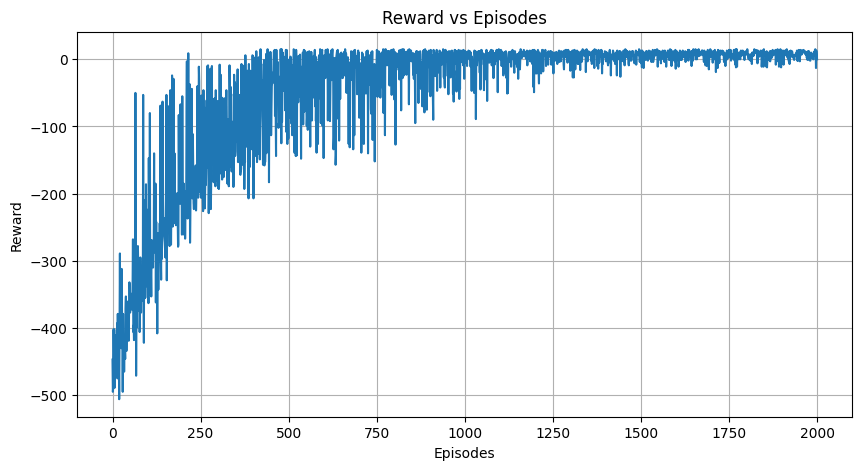

In [22]:
# Reward vs Episodes
plt.figure(figsize=(10, 5))

plt.plot(episode_rewards)

plt.xlabel("Episodes")
plt.ylabel("Reward")
plt.title("Reward vs Episodes")

plt.grid(True)
plt.show()

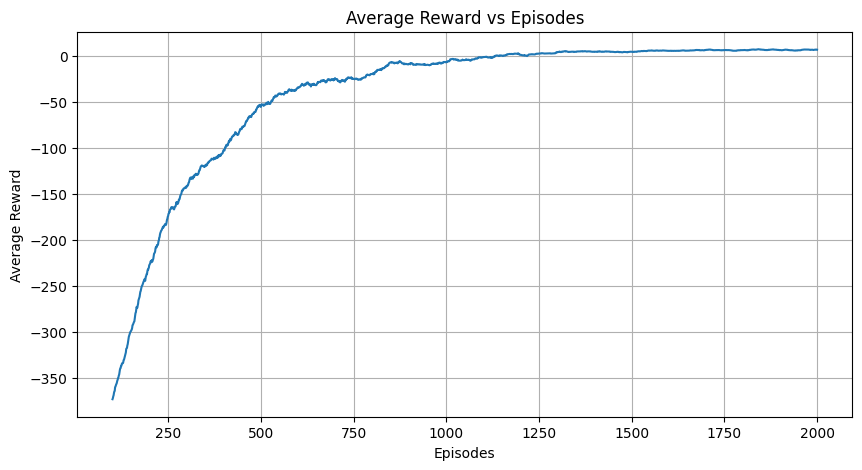

In [23]:
# Average Reward vs Episodes
window = 100

moving_average = np.convolve(
    episode_rewards,
    np.ones(window) / window,
    mode="valid"
)

plt.figure(figsize=(10, 5))

plt.plot(
    range(window, episodes + 1),
    moving_average
)

plt.xlabel("Episodes")
plt.ylabel("Average Reward")
plt.title("Average Reward vs Episodes")

plt.grid(True)
plt.show()

In [24]:
# Evaluate the Trained Agent
evaluation_episodes = 100

evaluation_rewards = []
evaluation_steps = []
successful_episodes = 0

for episode in range(evaluation_episodes):

    state = env.reset()

    total_reward = 0
    steps = 0

    while not env.done:

        action = np.argmax(q_table[state])

        next_state, reward, done = env.step(action)

        state = next_state

        total_reward += reward
        steps += 1

    evaluation_rewards.append(total_reward)
    evaluation_steps.append(steps)

    if reward == 20:
        successful_episodes += 1

In [25]:
# Final Performance
average_evaluation_reward = np.mean(evaluation_rewards)
average_evaluation_steps = np.mean(evaluation_steps)

success_rate = (
    successful_episodes / evaluation_episodes
) * 100

print("Evaluation Episodes:", evaluation_episodes)
print("Average Reward:", round(average_evaluation_reward, 2))
print("Average Steps:", round(average_evaluation_steps, 2))
print("Successful Episodes:", successful_episodes)
print("Success Rate:", round(success_rate, 2), "%")

Evaluation Episodes: 100
Average Reward: 6.44
Average Steps: 13.93
Successful Episodes: 97
Success Rate: 97.0 %


In [26]:
# Final Agent Demonstration
state = env.reset()

print("Initial State:", state)
env.render()

while not env.done:

    action = np.argmax(q_table[state])

    next_state, reward, done = env.step(action)

    print("Action:", ACTIONS[action])
    print("Reward:", reward)

    state = next_state

    env.render()

print("Final reward:", reward)

Initial State: 412

D . . . G
. . . . .
. . . . .
. . . . .
T . . . P

Taxi: (4, 0)
Passenger: (4, 4)
Destination: (0, 0)
Steps: 0
Action: RIGHT
Reward: -1

D . . . G
. . . . .
. . . . .
. . . . .
Y T . . P

Taxi: (4, 1)
Passenger: (4, 4)
Destination: (0, 0)
Steps: 1
Action: RIGHT
Reward: -1

D . . . G
. . . . .
. . . . .
. . . . .
Y . T . P

Taxi: (4, 2)
Passenger: (4, 4)
Destination: (0, 0)
Steps: 2
Action: RIGHT
Reward: -1

D . . . G
. . . . .
. . . . .
. . . . .
Y . . T P

Taxi: (4, 3)
Passenger: (4, 4)
Destination: (0, 0)
Steps: 3
Action: RIGHT
Reward: -1

D . . . G
. . . . .
. . . . .
. . . . .
Y . . . T

Taxi: (4, 4)
Passenger: (4, 4)
Destination: (0, 0)
Steps: 4
Action: PICKUP
Reward: -1

D . . . G
. . . . .
. . . . .
. . . . .
Y . . . T

Taxi: (4, 4)
Passenger: In Taxi
Destination: (0, 0)
Steps: 5
Action: UP
Reward: -1

D . . . G
. . . . .
. . . . .
. . . . T
Y . . . B

Taxi: (3, 4)
Passenger: In Taxi
Destination: (0, 0)
Steps: 6
Action: LEFT
Reward: -1

D . . . G
. . . . .
. 

In [27]:
# Optional Compact Results Table
print(" LAB 5 RESULTS ")
print("Application: Taxi Route Optimization")
print("Algorithm: Q-Learning")
print("Training Episodes:", episodes)
print("Learning Rate:", learning_rate)
print("Discount Factor:", discount_factor)
print("Final Epsilon:", round(epsilon, 4))
print("Training Average Reward (Last 100):",
      round(np.mean(episode_rewards[-100:]), 2))
print("Training Average Steps (Last 100):",
      round(np.mean(episode_steps[-100:]), 2))
print("Evaluation Episodes:", evaluation_episodes)
print("Evaluation Average Reward:",
      round(average_evaluation_reward, 2))
print("Evaluation Average Steps:",
      round(average_evaluation_steps, 2))
print("Successful Episodes:", successful_episodes)
print("Success Rate:", round(success_rate, 2), "%")

 LAB 5 RESULTS 
Application: Taxi Route Optimization
Algorithm: Q-Learning
Training Episodes: 2000
Learning Rate: 0.1
Discount Factor: 0.9
Final Epsilon: 0.0499
Training Average Reward (Last 100): 6.87
Training Average Steps (Last 100): 11.87
Evaluation Episodes: 100
Evaluation Average Reward: 6.44
Evaluation Average Steps: 13.93
Successful Episodes: 97
Success Rate: 97.0 %
